**Applying the Kriging Model to all seperate Sound Maps**

1. Import all necessary things and Store Kriging Model Class in variable.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from extract_sound import prepare_interpolation_data
from Ordinary_Kriging_Model import ExactAcousticKriging

Kriging_Model = ExactAcousticKriging()

2. Input the single point source sound map to the Kriging Model

Phones:   5 | Layout: random     | RMSE: 4.32 dB
Phones:   5 | Layout: grid       | RMSE: 4.25 dB
Phones:   5 | Layout: clustered  | RMSE: 6.44 dB
Phones:  10 | Layout: random     | RMSE: 3.58 dB
Phones:  10 | Layout: grid       | RMSE: 4.15 dB
Phones:  10 | Layout: clustered  | RMSE: 7.97 dB
Phones:  20 | Layout: random     | RMSE: 3.85 dB
Phones:  20 | Layout: grid       | RMSE: 2.74 dB
Phones:  20 | Layout: clustered  | RMSE: 5.50 dB
Phones:  50 | Layout: random     | RMSE: 2.96 dB
Phones:  50 | Layout: grid       | RMSE: 2.16 dB
Phones:  50 | Layout: clustered  | RMSE: 5.03 dB
Phones: 100 | Layout: random     | RMSE: 1.82 dB
Phones: 100 | Layout: grid       | RMSE: 1.14 dB
Phones: 100 | Layout: clustered  | RMSE: 4.39 dB


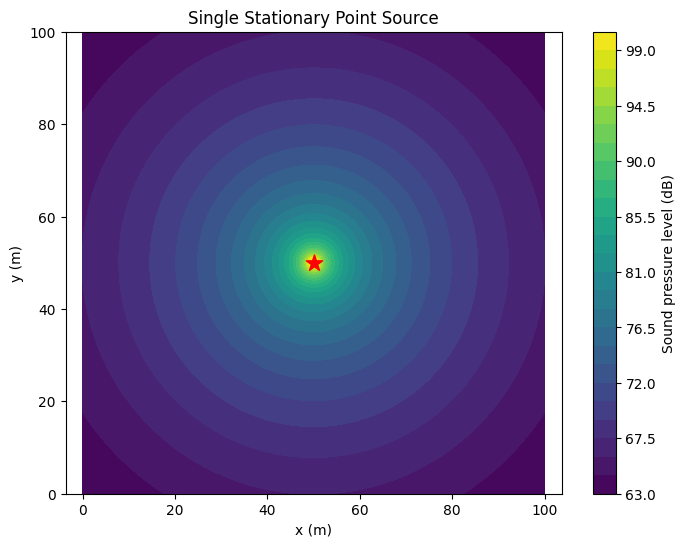

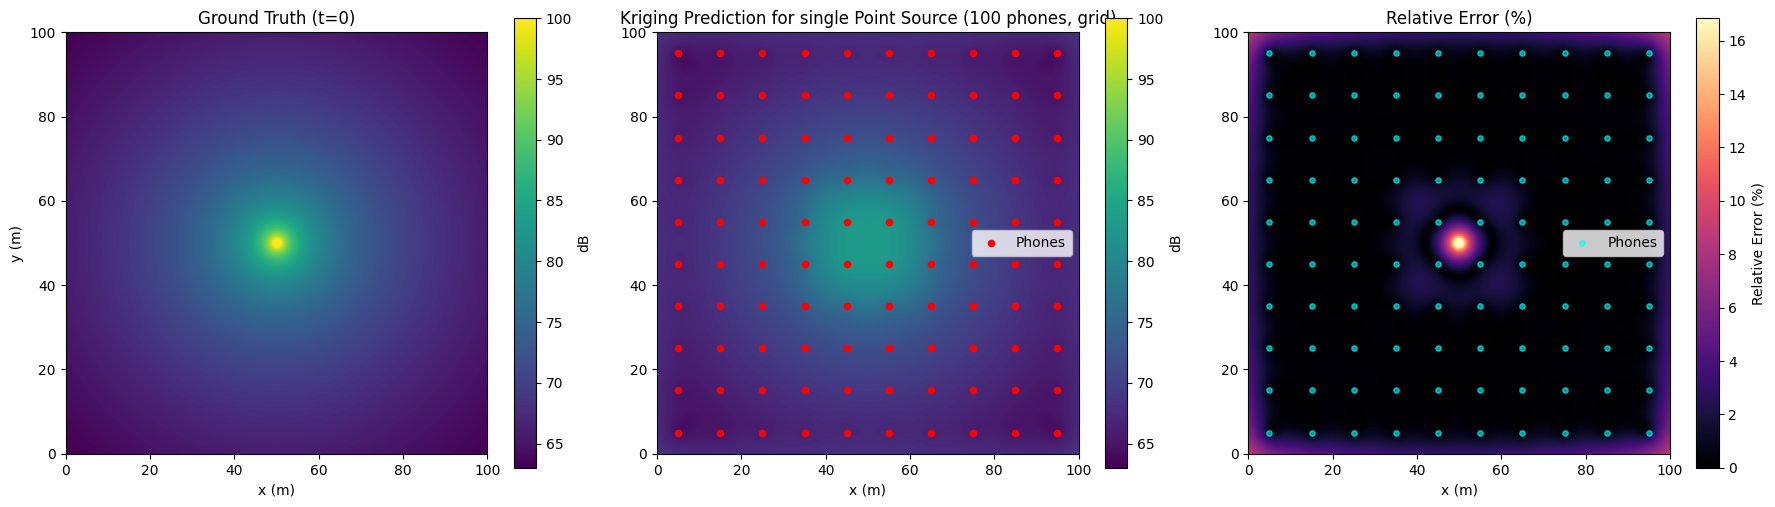

In [2]:
import point_source as sound_map

# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)


# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]
        
        # 1. Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"]
        )
        
        # 2. Compute Reconstruction Error (RMSE in dB across all time steps)
        rmse = np.sqrt(np.mean((predicted_levels - data["true_levels"]) ** 2))
        results.append({"count": count, "layout": layout, "rmse": rmse})
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {rmse:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# Shared scale for Ground Truth and Prediction
vmin = ground_truth_2d.min()
vmax = ground_truth_2d.max()

#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[0].set_title("Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for single Point Source ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()


3. Input the multiple point sources sound map to the Kriging Model

Phones:   5 | Layout: random     | RMSE: 4.62 dB
Phones:   5 | Layout: grid       | RMSE: 4.91 dB
Phones:   5 | Layout: clustered  | RMSE: 11.59 dB
Phones:  10 | Layout: random     | RMSE: 5.00 dB
Phones:  10 | Layout: grid       | RMSE: 5.00 dB
Phones:  10 | Layout: clustered  | RMSE: 9.55 dB
Phones:  20 | Layout: random     | RMSE: 3.76 dB
Phones:  20 | Layout: grid       | RMSE: 3.05 dB
Phones:  20 | Layout: clustered  | RMSE: 12.92 dB
Phones:  50 | Layout: random     | RMSE: 3.10 dB
Phones:  50 | Layout: grid       | RMSE: 46.83 dB
Phones:  50 | Layout: clustered  | RMSE: 12.95 dB
Phones: 100 | Layout: random     | RMSE: 1.82 dB
Phones: 100 | Layout: grid       | RMSE: 1.40 dB
Phones: 100 | Layout: clustered  | RMSE: 9.03 dB


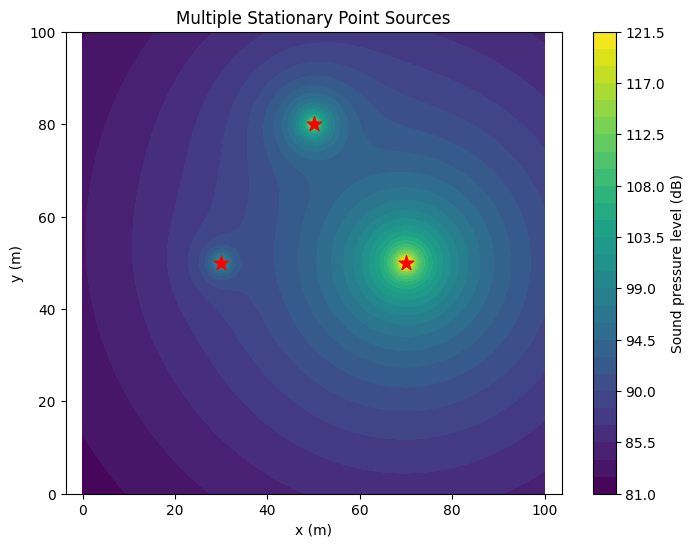

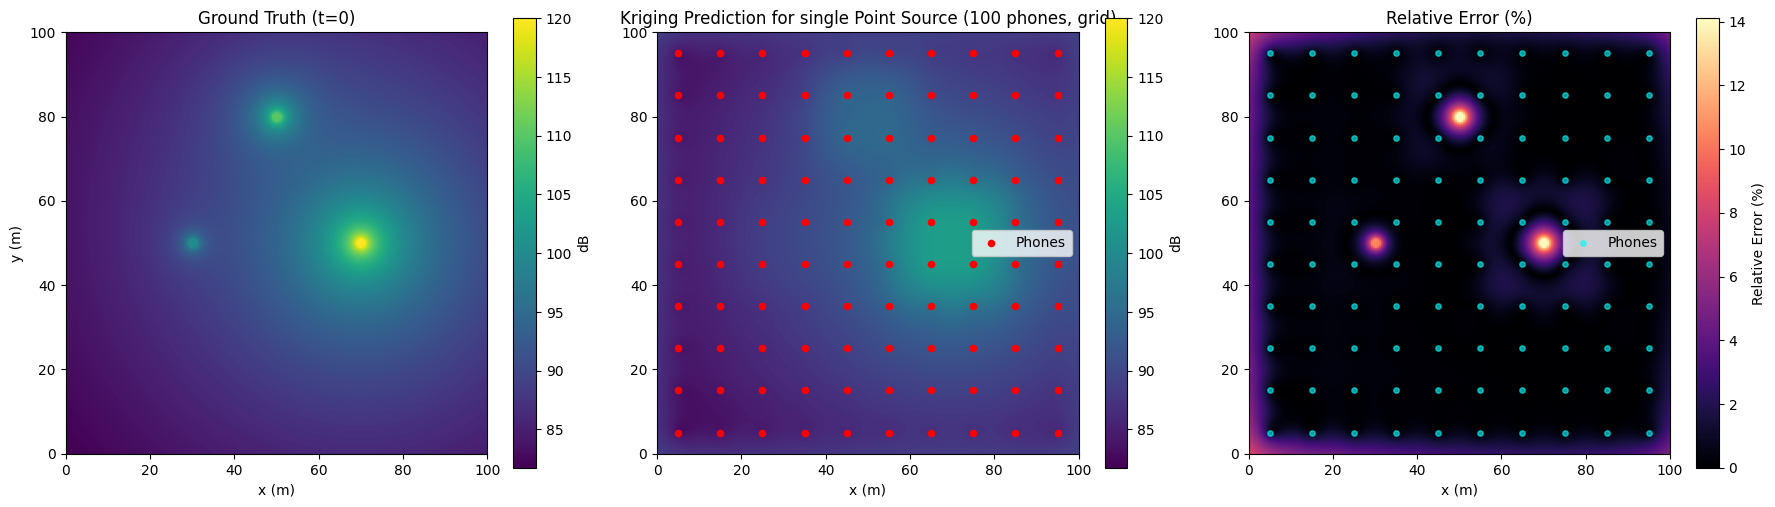

In [3]:
import multiple_point_sources as sound_map


# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)



# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]
        
        # 1. Run interpolation
        predicted_levels = Kriging_Model.fit_predict(
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"]
        )
        
        # 2. Compute Reconstruction Error (RMSE in dB across all time steps)
        rmse = np.sqrt(np.mean((predicted_levels - data["true_levels"]) ** 2))
        results.append({"count": count, "layout": layout, "rmse": rmse})
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {rmse:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = Kriging_Model.fit_predict(
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# Shared scale for Ground Truth and Prediction
vmin = ground_truth_2d.min()
vmax = ground_truth_2d.max()

#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[0].set_title("Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for single Point Source ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()

4. Input the single moving point source sound map to the Kriging Model

Phones:   5 | Layout: random     | RMSE: 6.31 dB
Phones:   5 | Layout: grid       | RMSE: 6.01 dB
Phones:   5 | Layout: clustered  | RMSE: 6.13 dB
Phones:  10 | Layout: random     | RMSE: 4.83 dB
Phones:  10 | Layout: grid       | RMSE: 5.86 dB
Phones:  10 | Layout: clustered  | RMSE: 6.15 dB
Phones:  20 | Layout: random     | RMSE: 6.75 dB
Phones:  20 | Layout: grid       | RMSE: 5.08 dB
Phones:  20 | Layout: clustered  | RMSE: 5.93 dB
Phones:  50 | Layout: random     | RMSE: 14.99 dB
Phones:  50 | Layout: grid       | RMSE: 3.42 dB
Phones:  50 | Layout: clustered  | RMSE: 5.56 dB
Phones: 100 | Layout: random     | RMSE: 14.48 dB
Phones: 100 | Layout: grid       | RMSE: 23.83 dB
Phones: 100 | Layout: clustered  | RMSE: 6.47 dB


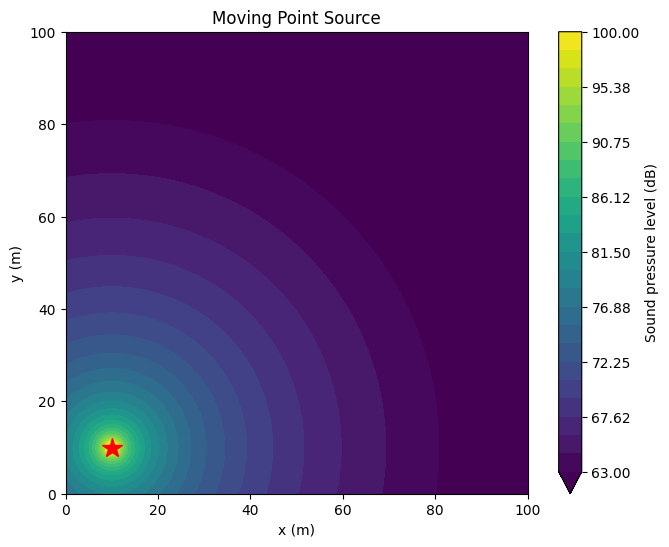

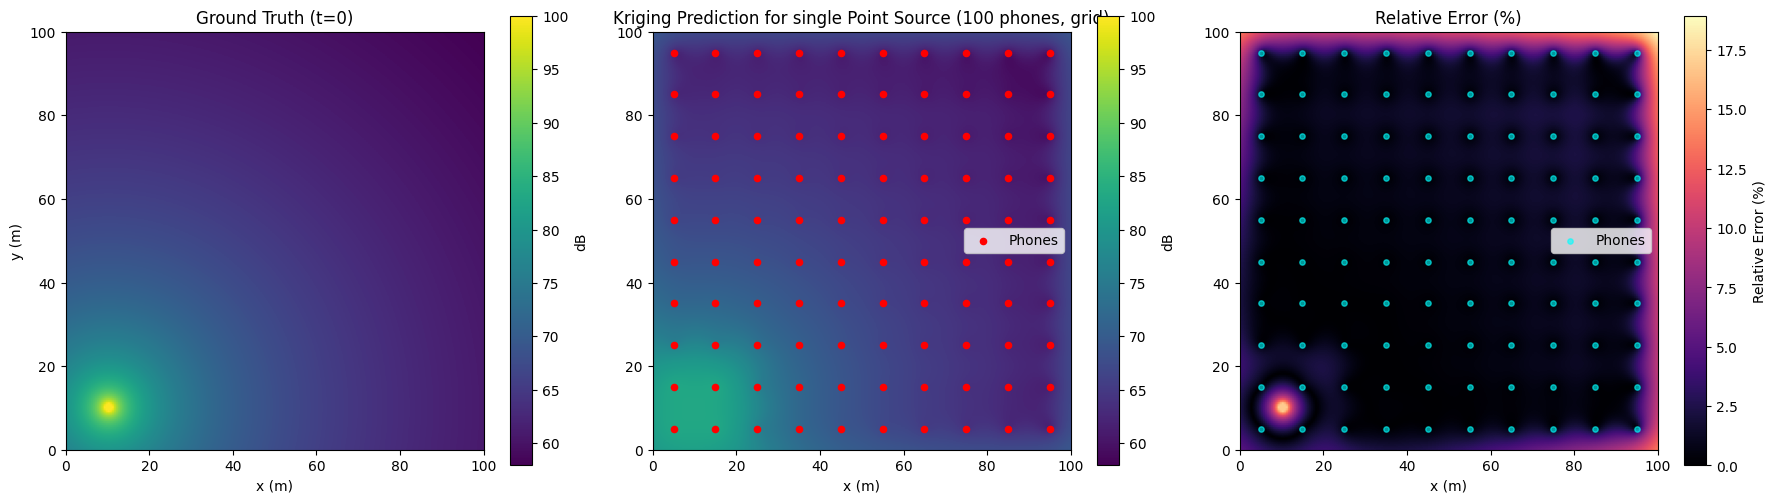

In [4]:
import single_moving_point_source as sound_map


# 1. Load the sound maps and grid
sound_maps = sound_map.sound_maps
x = sound_map.x
y = sound_map.y

source_x = sound_map.source_x_positions
source_y = sound_map.source_y


# 2. Define phone configurations
phone_counts = [5, 10, 20, 50, 100]
layouts = ["random", "grid", "clustered"]


# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)



# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]
        
        # 1. Run interpolation
        predicted_levels = ExactAcousticKriging.fit_predict(ExactAcousticKriging(),
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"]
        )
        
        # 2. Compute Reconstruction Error (RMSE in dB across all time steps)
        rmse = np.sqrt(np.mean((predicted_levels - data["true_levels"]) ** 2))
        results.append({"count": count, "layout": layout, "rmse": rmse})
        print(f"Phones: {count:3d} | Layout: {layout:10s} | RMSE: {rmse:.2f} dB")


N_phones = 100
layout_type = "grid"
# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
pred_map = ExactAcousticKriging.fit_predict(ExactAcousticKriging(),
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
grid_shape = (len(y), len(x))
reconstructed_2d = pred_map[0].reshape(grid_shape)
ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# Shared scale for Ground Truth and Prediction
vmin = ground_truth_2d.min()
vmax = ground_truth_2d.max()

#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[0].set_title("Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax)
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for single Point Source ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend()
plt.colorbar(im1, ax=axes[1], label="dB")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()

Phones:  10 | Layout: random     | Audience RMSE: 2.69 dB
Phones:  10 | Layout: grid       | Audience RMSE: 2.57 dB
Phones:  10 | Layout: clustered  | Audience RMSE: 8.09 dB
Phones:  30 | Layout: random     | Audience RMSE: 2.09 dB
Phones:  30 | Layout: grid       | Audience RMSE: 2.56 dB
Phones:  30 | Layout: clustered  | Audience RMSE: 7.74 dB
Phones:  50 | Layout: random     | Audience RMSE: 1.64 dB
Phones:  50 | Layout: grid       | Audience RMSE: 1.51 dB
Phones:  50 | Layout: clustered  | Audience RMSE: 5.81 dB
Phones: 100 | Layout: random     | Audience RMSE: 1.21 dB
Phones: 100 | Layout: grid       | Audience RMSE: 0.85 dB
Phones: 100 | Layout: clustered  | Audience RMSE: 5.44 dB
Phones: 250 | Layout: random     | Audience RMSE: 0.60 dB
Phones: 250 | Layout: grid       | Audience RMSE: 0.31 dB
Phones: 250 | Layout: clustered  | Audience RMSE: 4.68 dB


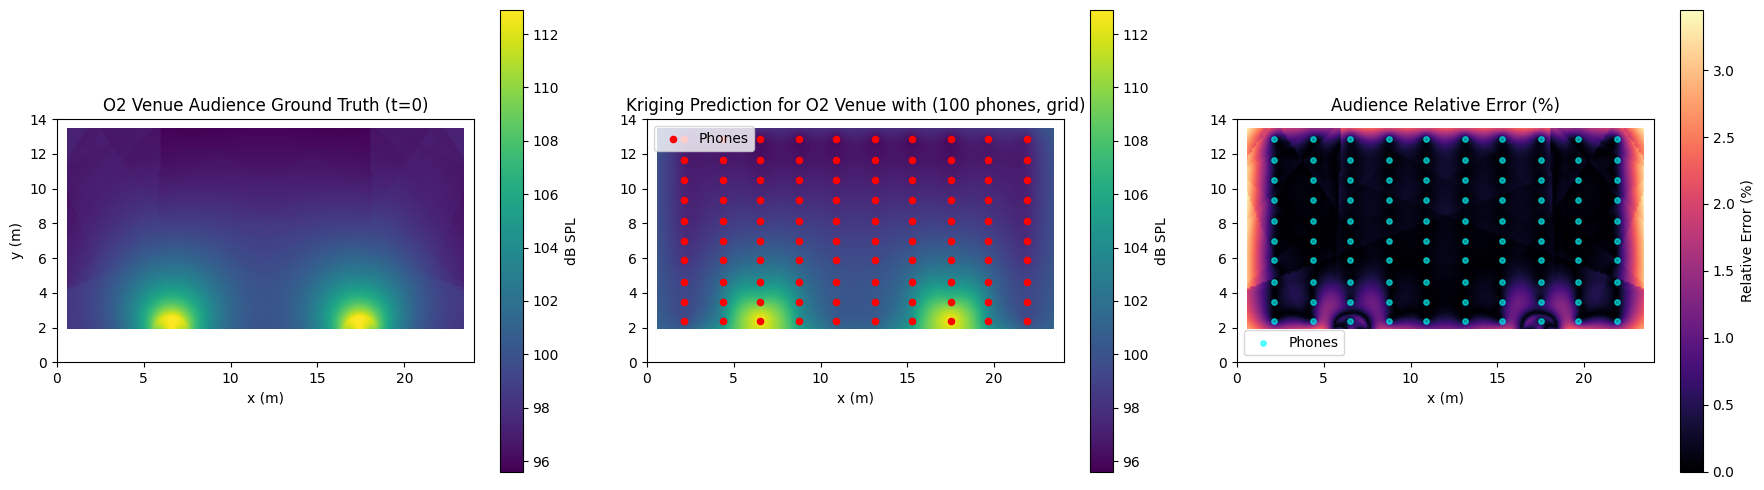

In [5]:
import concert_map as venue_sim
import test_input_for_interpolate_venue as venue_data


# 1. Load the sound maps and grid
#sound_maps = sound_map.sound_maps
#x = sound_map.x
#y = sound_map.y

#source_x = sound_map.source_x_positions
#source_y = sound_map.source_y

x = venue_sim.x
y = venue_sim.y
grid_shape = (len(y), len(x))

prepared_data = venue_data.prepared_data

# 2. Define phone configurations
phone_counts = [10, 30, 50, 100, 250]
layouts = ["random", "grid", "clustered"]

"""
# 3. Prepare interpolation data (THIS WILL BE INPUT INTO THE INERPOLATION MODELS)
prepared_data = prepare_interpolation_data(
    sound_maps=sound_maps,
    x=x,
    y=y,
    phone_counts=phone_counts,
    layouts=layouts
)
"""


# Track benchmarking results
results = []

for count in phone_counts:
    for layout in layouts:
        data = prepared_data[(count, layout)]

        # Ensure 2D inputs
        phone_levels = np.atleast_2d(data["phone_levels"])
        true_levels = np.atleast_2d(data["true_levels"])
        #allowed_mask = data["allowed_mask"]
        
        # Run interpolation
        predicted_levels = ExactAcousticKriging.fit_predict(ExactAcousticKriging(),
            phone_positions=data["phone_positions"],
            phone_levels=data["phone_levels"],
            query_positions=data["query_positions"]
        )

        # Calculate RMSE specifically within the audience listening area
        audience_rmse = np.sqrt(np.mean((predicted_levels - true_levels) ** 2))
        
        # Compute Reconstruction Error (RMSE in dB across all time steps)
        #rmse = np.sqrt(np.mean((predicted_levels - data["true_levels"]) ** 2))
        results.append({
            "count": count, 
            "layout": layout, 
            "audience_rmse": audience_rmse
            })
        print(f"Phones: {count:3d} | Layout: {layout:10s} | Audience RMSE: {audience_rmse:.2f} dB")


N_phones = 100
layout_type = "grid"

# 3. Visualize a specific reconstruction (Time step 0 for 20 clustered phones)
target_config = prepared_data[(N_phones, layout_type)]
target_phone_levels = np.atleast_2d(target_config["phone_levels"])
target_true_levels = np.atleast_2d(target_config["true_levels"])
mask_2d = np.asarray(target_config["allowed_mask"]).reshape(grid_shape)

pred_map = ExactAcousticKriging.fit_predict(ExactAcousticKriging(),
    target_config["phone_positions"],
    target_config["phone_levels"],
    target_config["query_positions"]
)

# Unpack 17390 audience points back into full (len(y), len(x)) grids
ground_truth_2d = np.full(grid_shape, np.nan)
reconstructed_2d = np.full(grid_shape, np.nan)

ground_truth_2d[mask_2d] = target_true_levels[0]
reconstructed_2d[mask_2d] = pred_map[0]

# Reshape to 2D
#ground_truth_2d = target_true_levels[0].reshape(grid_shape).copy()
#reconstructed_2d = pred_map[0].reshape(grid_shape).copy()

# Reshape the flat 1D query array (M,) back to 2D grid (len(y), len(x))
#grid_shape = (len(y), len(x))
#reconstructed_2d = pred_map[0].reshape(grid_shape)
#ground_truth_2d = target_config["true_levels"][0].reshape(grid_shape)

# Compute Relative Error (%)
relative_error_2d = (np.abs(reconstructed_2d - ground_truth_2d) / np.abs(ground_truth_2d)) * 100

# Mask out areas outside the audience zone for clean display
#ground_truth_2d[~mask_2d] = np.nan
#reconstructed_2d[~mask_2d] = np.nan
#relative_error_2d[~mask_2d] = np.nan

# nanmin/nanmax ensure NaNs outside the audience don't corrupt color limits
vmin = np.nanmin(ground_truth_2d)
vmax = np.nanmax(ground_truth_2d)

# Shared scale for Ground Truth and Prediction
#vmin = ground_truth_2d.min()
#vmax = ground_truth_2d.max()

#1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

im0 = axes[0].imshow(ground_truth_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[0].set_title("O2 Venue Audience Ground Truth (t=0)")
axes[0].set_xlabel("x (m)")
axes[0].set_ylabel("y (m)")
plt.colorbar(im0, ax=axes[0], label="dB SPL")

im1 = axes[1].imshow(reconstructed_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], vmin=vmin, vmax=vmax, cmap="viridis")
axes[1].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="red", s=20, label="Phones")
axes[1].set_title(f"Kriging Prediction for O2 Venue with ({N_phones} phones, {layout_type})")
axes[1].set_xlabel("x (m)")
axes[1].legend(loc="upper left")
plt.colorbar(im1, ax=axes[1], label="dB SPL")

im2 = axes[2].imshow(relative_error_2d, origin="lower", extent=[x.min(), x.max(), y.min(), y.max()], cmap="magma", vmin=0)
axes[2].scatter(target_config["phone_positions"][:, 0], target_config["phone_positions"][:, 1], color="cyan", s=15, alpha=0.6, label="Phones")
axes[2].set_title("Audience Relative Error (%)")
axes[2].set_xlabel("x (m)")
axes[2].legend()
plt.colorbar(im2, ax=axes[2], label="Relative Error (%)")


plt.tight_layout()
plt.show()